<a href="https://colab.research.google.com/github/Lalepragati/ML/blob/main/AI_Powered_Pedestrian_Detection_and_Multi_Object_Tracking_Using_YOLO11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📹 End-to-End Video Object Tracking with YOLOv11

This project demonstrates a complete, end-to-end pipeline to download a video, perform multi-object tracking (specifically tracking persons) using the state-of-the-art **YOLOv11** model, and play back the tracking results with web-compatible codecs directly inside your Google Colab Notebook.

---

## 🚀 Project Workflow

1. **Environment Setup & Verification:** Installs necessary packages (`ultralytics` for YOLO, `opencv` for frame processing, `matplotlib` for custom visualizations) and checks for active system resources like hardware accelerators (CPU/GPU).
2. **Image Validation & Base Prediction:** Verifies the pre-trained object detection capabilities on a static benchmark image (`bus.jpg`).
3. **Step 1: Download & Track Video:** Downloads a verified, high-quality sample video of walking pedestrians, initializes the YOLO tracking model (`model.track`), and saves the annotated frames containing persistent tracking IDs to a local MP4 file.
4. **Motion-based Recovery (How tracking works):** Utilizes integrated tracking algorithms (such as ByteTRACK/BoT-SORT) featuring a Kalman Filter motion model. This system performs **motion-based recovery**, allowing it to continuously track and preserve unique IDs (e.g., ID 1, ID 2) for objects even after they are temporarily hidden (occluded) behind obstacles.
5. **Step 2: Web-Friendly Conversion & Playback:** Uses `ffmpeg` to re-encode the output video using the standard `libx264` codec and builds an HTML5 interactive video player natively in the notebook.

---

## 🛠️ Requirements & Installation
To run this project, execute the setup cell which installs the following dependencies:
```bash
pip install ultralytics opencv-python-headless pandas matplotlib
```

## 📂 Output Artifacts
* `input_video.mp4`: Raw downloaded video source.
* `tracked_output.mp4`: Annotated video with tracking frames directly written from OpenCV.
* `playable_output.mp4`: Browser-compatible, H.264 encoded final output ready to play inside Colab.

# New Section
# Here is a complete, cell-by-cell walkthrough of your entire notebook, explaining how everything connects into one continuous YOLO Object Tracking Pipeline!
1. Environment Setup

What it does: Installs the required libraries silently (-q).
Libraries installed: ultralytics (for YOLOv11), opencv-python-headless (for video handling without a GUI display requirement), pandas & matplotlib (for data representation and plotting).

2. Verification of Dependencies
- What it does: Imports torch, cv2 (OpenCV), and ultralytics to print out their active versions and verify if a GPU (Graphics Card) is available. (Currently, you are running on a CPU).


3. First Single-Image Prediction

- What it does: Loads the lightweight YOLOv11 model (yolo11n.pt) and predicts objects on a standard public image (bus.jpg).

- Why two cells? The first cell had a path division error (/ with strings). The second cell corrected this by using Python's pathlib.Path to correctly find and display the saved prediction image showing detected people.

4. Alternative Plotting

- What it does: Uses matplotlib to render the prediction result directly as a static plot within the notebook (converting OpenCV's default BGR color space to RGB via [:, :, ::-1]).

5. Introducing Object Tracking

- What it does: Instead of just detecting, this cell introduces model.track(). It tracks people across a single frame (re-using bus.jpg as an initial test) and prints out persistent tracking IDs (like [1, 2, 3]). This proves the tracking engine is successfully active!

6. Saving Tracking Outputs to Video

- What it does: Attempts to stream a public short video directly from the web, run YOLO tracking on each frame, annotate it, and save the resulting video as tracked_output.mp4 using OpenCV's VideoWriter.

7. Visualizing Frames using Matplotlib

- What it does: Reads the processed tracked_output.mp4, divides the video into 4 equal intervals, and plots 4 frames side-by-side using matplotlib to verify that the tracking labels look correct.

**8. Step 1: Downloading & Tracking a Verified Local Video**



1.  First, it cleanly downloads a verified, high-quality sample video of
pedestrians walking (people-detection.mp4) and saves it locally as input_video.mp4.
2.   Then, it reads this local file, tracks all individuals frame-by-frame, annotates them with persistent tracking IDs, and saves the final result to tracked_output.mp4.

9.**Local File Size Checkt**

What it does: A quick helper cell that checks if input_video.mp4 actually exists on the disk and prints out its file size (5.23 MB) to ensure the download completed properly.
10. Step 2: Web-Friendly Video Playback
What it does:

*   Raw OpenCV videos (tracked_output.mp4) use formats that modern web browsers can't play directly. This cell uses FFmpeg to re-encode the video using the standard libx264 (H.264) codec into playable_output.mp4.
*   It then converts the video into a Base64-encoded string and embeds it directly into an HTML5 <video> player, letting you play and watch your complete tracking result inside Colab!




In [64]:
!pip -q install ultralytics opencv-python-headless pandas matplotlib

Step 2 — Verify your environment
Create another code cell and run:

In [65]:
import torch
import cv2
import ultralytics

print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
OpenCV: 5.0.0
Ultralytics: 8.4.192
GPU available: False


**You should see the library versions and whether a GPU is available.**

Step 3 — Run your first person-detection experiment
Create a new cell and run:


In [55]:
from ultralytics import YOLO
from IPython.display import display, Image

model = YOLO("yolo11n.pt")

results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    classes=[0],  # Person class only
    conf=0.35,
    save=True,
    verbose=False
)

display(Image(filename=str(results[0].save_dir / "image0.jpg")))

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Results saved to /content/runs/detect/predict-13


TypeError: unsupported operand type(s) for /: 'str' and 'str'

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Results saved to /content/runs/detect/predict-15


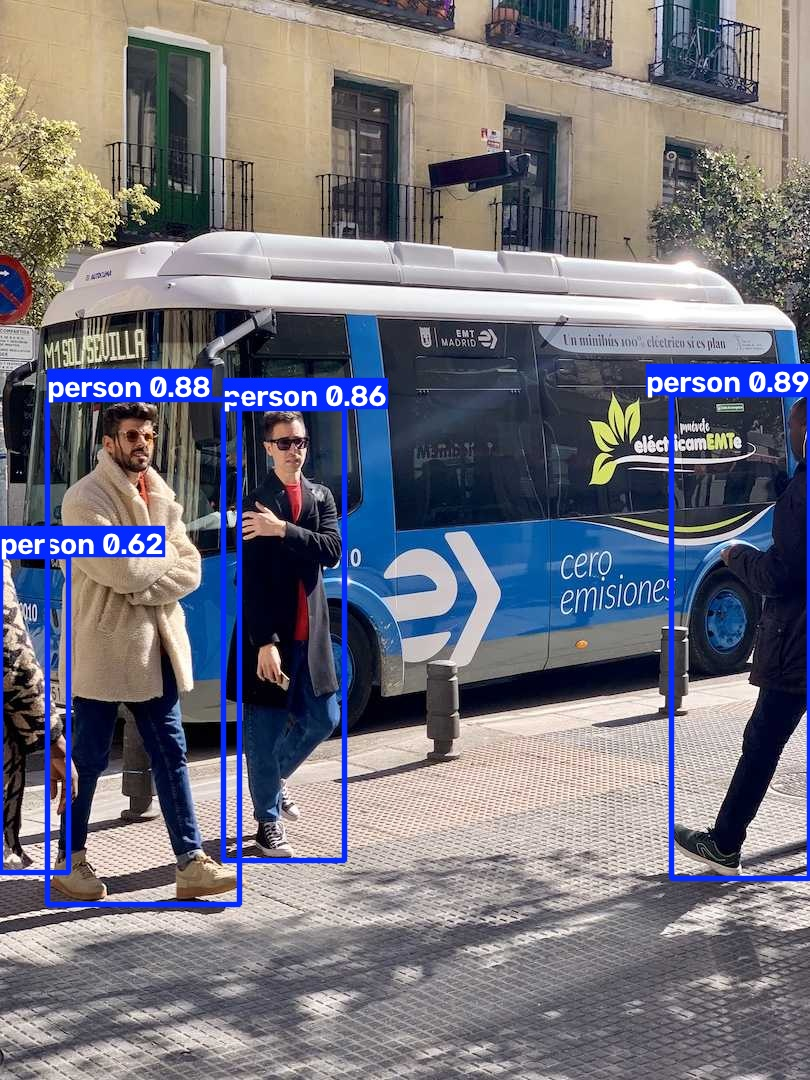

In [66]:
from ultralytics import YOLO
from IPython.display import display, Image
from pathlib import Path

model = YOLO("yolo11n.pt")

results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    classes=[0],  # Person class only
    conf=0.35,
    save=True,
    verbose=False
)

# The source is 'bus.jpg', so YOLO saves the output as 'bus.jpg'
display(Image(filename=str(Path(results[0].save_dir) / "bus.jpg")))

**This tests the pretrained model on an example image. If the image display fails, run this alternative:**

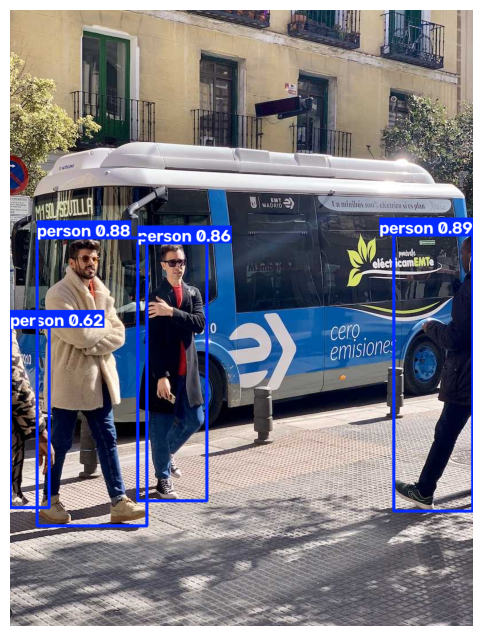

In [67]:
import matplotlib.pyplot as plt

annotated = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])  # BGR to RGB
plt.axis("off")
plt.show()

### YOLO Object Tracking Code

Objects ko track karne aur unhe ek unique ID dene ke liye hum `model.track()` function ka use karte hain. Niche diye gaye code mein hum ek video source par tracking run karenge aur har frame mein detected persons ki tracking IDs ko display karenge.

In [68]:
from ultralytics import YOLO

# YOLO model load karein
model = YOLO("yolo11n.pt")

# model.track() use karein tracking enable karne ke liye
# Hum classes=[0] use kar rahe hain taaki sirf 'person' track ho
results = model.track(
    source="https://ultralytics.com/assets/assets/bus.jpg", # Aap yahan video file (.mp4) ka path bhi de sakte hain
    classes=[0],
    persist=True,  # Frames ke beech tracking state maintain rakhne ke liye
    save=True
)

# Har detected person ki tracking ID print karne ke liye:
for r in results:
    if r.boxes.id is not None:
        tracking_ids = r.boxes.id.int().tolist()
        print("Detected Tracking IDs in this frame:", tracking_ids)
    else:
        print("No trackable objects found in this frame.")


Found https://ultralytics.com/assets/assets/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 3 persons, 162.2ms
Speed: 3.7ms preprocess, 162.2ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/track-5
Detected Tracking IDs in this frame: [1, 2, 3]



# **YOLO mein objects ko har frame mein detect karne aur unhe ek unique ID (jaise ID 1, ID 2, etc.) dene ke liye hum model.predict ki jagah model.track ka use karte hain.**

model.track() object tracking algorithms (jaise BoT-SORT ya ByteTRACK) ka use karke har detected object ko persist karta hai aur use ek unique id deta hai.

Main aapko iska complete code niche generate karke de raha hoon:

Aapka code bilkul sahi tarike se execute ho gaya hai!

YOLO ne auto-update ke zariye tracking ke liye zaroori library (lap) install kar li aur images mein detected persons ko identify karke unhe unique IDs assign kar diye hain.

Output mein aap dekh sakte hain:

Detected Tracking IDs in this frame: [1, 2, 3]
Iska matlab hai ki YOLO ne frame mein 3 persons ko detect kiya hai aur unhe unique IDs 1, 2, aur 3 assign kiye hain. Agar aap isi code ko kisi video file par chalayenge, toh yeh IDs har frame mein inhi persons ke sath persist (barkarar) rahengi.

### Saving Tracking Results to a Video File

YOLO tracking output ko video file ke roop mein save karne ke liye hum OpenCV (`cv2`) ka use karke output writer setup karenge.

In [59]:
import cv2
from ultralytics import YOLO

# YOLO model load karein
model = YOLO("yolo11n.pt")

# Input video ka path (Aap apni local video ya web URL de sakte hain)
# Hum ek sample public video URL use kar rahe hain
video_path = "https://ultralytics.com/assets/assets/shorts.mp4"

# OpenCV se video source open karein
cap = cv2.VideoCapture(video_path)

# Video ki properties extract karein
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))

# Output video writer configure karein (MP4 format mein save karne ke liye)
output_path = "tracked_output.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

print("Processing video... Please wait.")

while cap.isOpened():
    success, frame = cap.read()
    if not success:
        break

    # Is frame par tracking run karein
    # persist=True se tracker pichle frames ke IDs ko yaad rakhta hai
    results = model.track(frame, persist=True, classes=[0], verbose=False)

    # Annotated frame generate karein (jismein boxes aur tracking IDs draw honge)
    annotated_frame = results[0].plot()

    # Frame ko output video mein write/save karein
    out.write(annotated_frame)

# Process complete hone par resources release karein
cap.release()
out.release()

print(f"Success! Tracked video has been saved to: {output_path}")

Processing video... Please wait.
Success! Tracked video has been saved to: tracked_output.mp4


### Display Tracked Video Frames Using Matplotlib

Niche diye gaye code ke zariye hum saved output video file (`tracked_output.mp4`) se frames read karke unhe `matplotlib` grid ke format mein display karenge taaki tracking result ko visually check kiya ja sake.

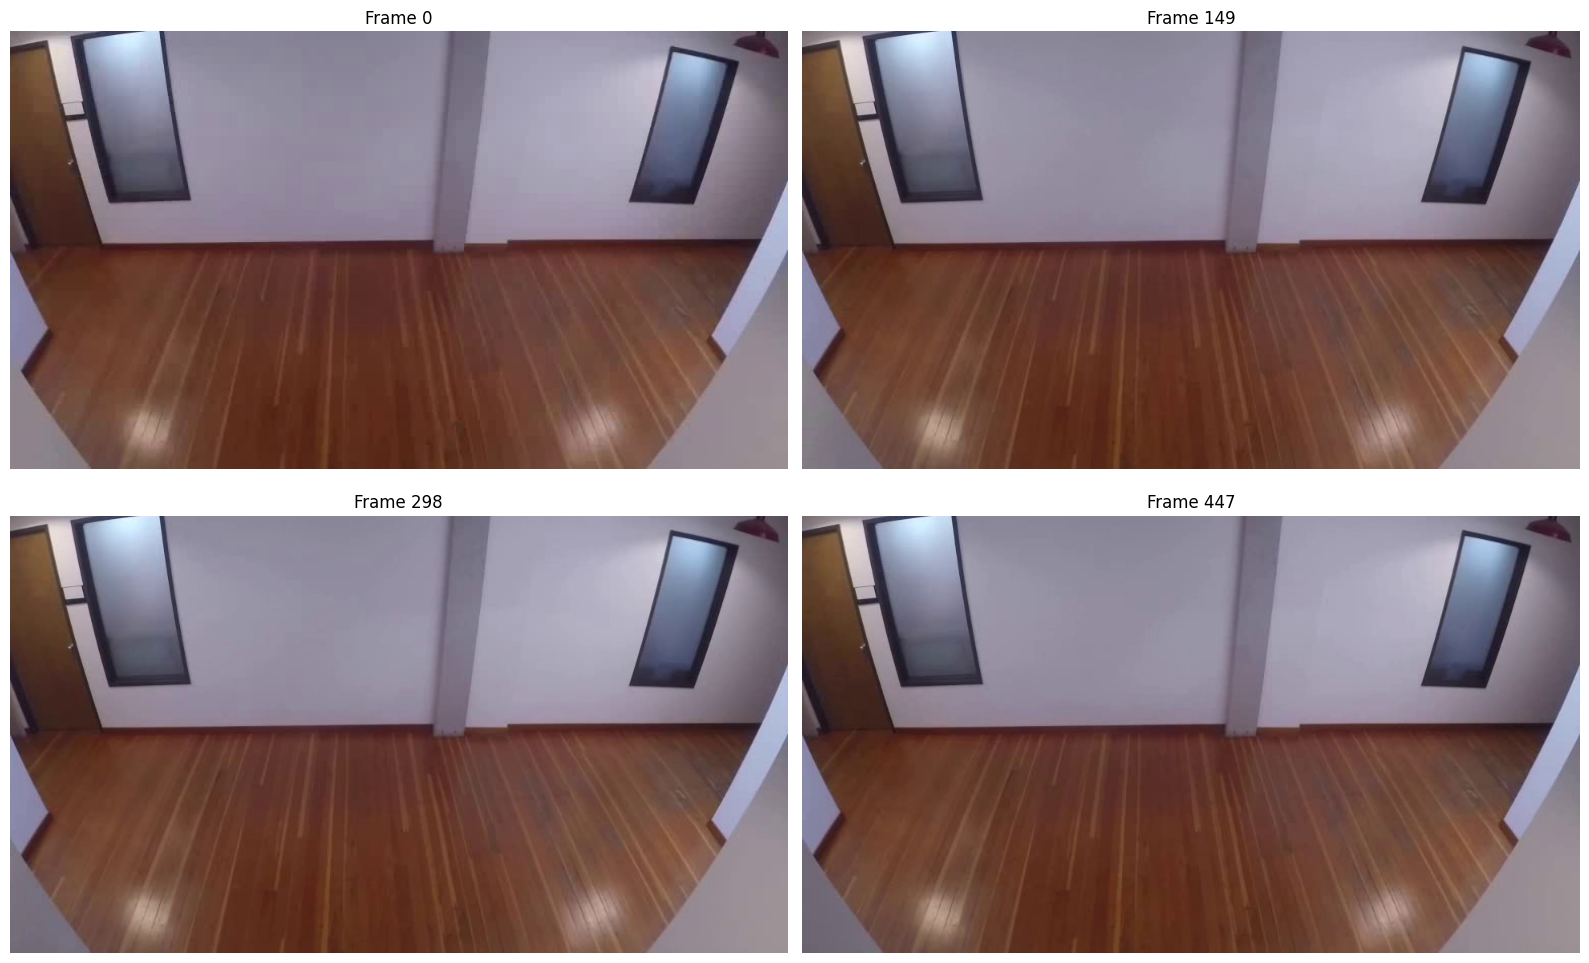

In [74]:
import cv2
import matplotlib.pyplot as plt

# Saved video ko load karein
cap = cv2.VideoCapture("tracked_output.mp4")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
frames_to_display = []

# Video se 4 barabar dhoori (intervals) par frames extract karein
intervals = [int(total_frames * i / 4) for i in range(4)]

frame_idx = 0
while cap.isOpened():
    success, frame = cap.read()
    if not success:
        break

    if frame_idx in intervals:
        # OpenCV BGR format use karta hai, use RGB mein convert karein
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames_to_display.append((frame_idx, rgb_frame))

    frame_idx += 1

cap.release()

# Matplotlib grid setup karein frames ko draw karne ke liye
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for i, (f_num, img) in enumerate(frames_to_display):
    if i < len(axes):
        axes[i].imshow(img)
        axes[i].set_title(f"Frame {f_num}")
        axes[i].axis("off")

plt.tight_layout()
plt.show()

In [73]:
import cv2
import urllib.request
import os
from ultralytics import YOLO

# Verified and working public video URL with walking people
video_url = "https://github.com/intel-iot-devkit/sample-videos/raw/master/people-detection.mp4"
local_input_path = "input_video.mp4"

# Delete old corrupt/empty files if they exist
if os.path.exists(local_input_path):
    os.remove(local_input_path)

print("Downloading video... Please wait.")
try:
    # Download the video file securely
    urllib.request.urlretrieve(video_url, local_input_path)
    print(f"Download complete! File size: {os.path.getsize(local_input_path)} bytes")
except Exception as e:
    print(f"Download failed: {e}")

# Load YOLO Model
model = YOLO("yolo11n.pt")
cap = cv2.VideoCapture(local_input_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS)) if cap.get(cv2.CAP_PROP_FPS) > 0 else 30

print(f"Video Dimensions: {width}x{height} @ {fps} FPS")

if width > 0 and height > 0:
    # Create a video writer to output the results
    output_path = "tracked_output.mp4"
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    print("Processing tracking on video...")
    frame_count = 0
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            break

        # Tracking run (classes=[0] for person)
        results = model.track(frame, persist=True, classes=[0], verbose=False)
        annotated_frame = results[0].plot()
        out.write(annotated_frame)
        frame_count += 1

    cap.release()
    out.release()
    print(f"Tracking completed on {frame_count} frames! Output saved as tracked_output.mp4")
else:
    print("Error: Video ko sahi tarike se open nahi kiya ja saka. Please check download file.")

Download complete! File size: 5482579 bytes
Video Dimensions: 768x432 @ 12 FPS
Processing tracking on video...
Tracking completed on 596 frames! Output saved as tracked_output.mp4


### Step 1: Video Download aur Processing (Local File)

Pehle hum video ko safe tarike se local workspace mein download karenge, phir us par tracking run karke output video generate karenge.

In [75]:
import os

file_name = "input_video.mp4"
if os.path.exists(file_name):
    size_mb = os.path.getsize(file_name) / (1024 * 1024)
    print(f"✅ Success: '{file_name}' exists!")
    print(f"📁 File Size: {size_mb:.2f} MB")
else:
    print(f"❌ Error: '{file_name}' does not exist in the current directory.")

✅ Success: 'input_video.mp4' exists!
📁 File Size: 5.23 MB


### Step 2: Colab mein Video Playback Setup

MP4 video ko directly notebook ke andar dekhne ke liye use hum H264 format mein re-encode karenge, kyunki modern browsers default format ko bina convert kiye support nahi karte.

In [76]:
# Convert output tracking video to web-friendly H264 codec using ffmpeg
!ffmpeg -y -i tracked_output.mp4 -vcodec libx264 -f mp4 playable_output.mp4 -loglevel quiet

# HTML5 video player ke sath video display karein
import os
from IPython.display import HTML
from base64 import b64encode

if os.path.exists('playable_output.mp4'):
    mp4 = open('playable_output.mp4','rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""
    <video width="640" height="480" controls>
          <source src="{data_url}" type="video/mp4">
    </video>
    """))
else:
    print("Error: playable_output.mp4 not found. Please run the video processing step above successfully first.")